Evaluation: XGBoost...
Evaluation: RandomForest...
Evaluation: ExtraTrees...
Evaluation: KNN...
Evaluation: MLP...
Evaluation: SVM...
Evaluation: LightGBM...
Evaluation: AdaBoost...
Evaluation: CatBoost...


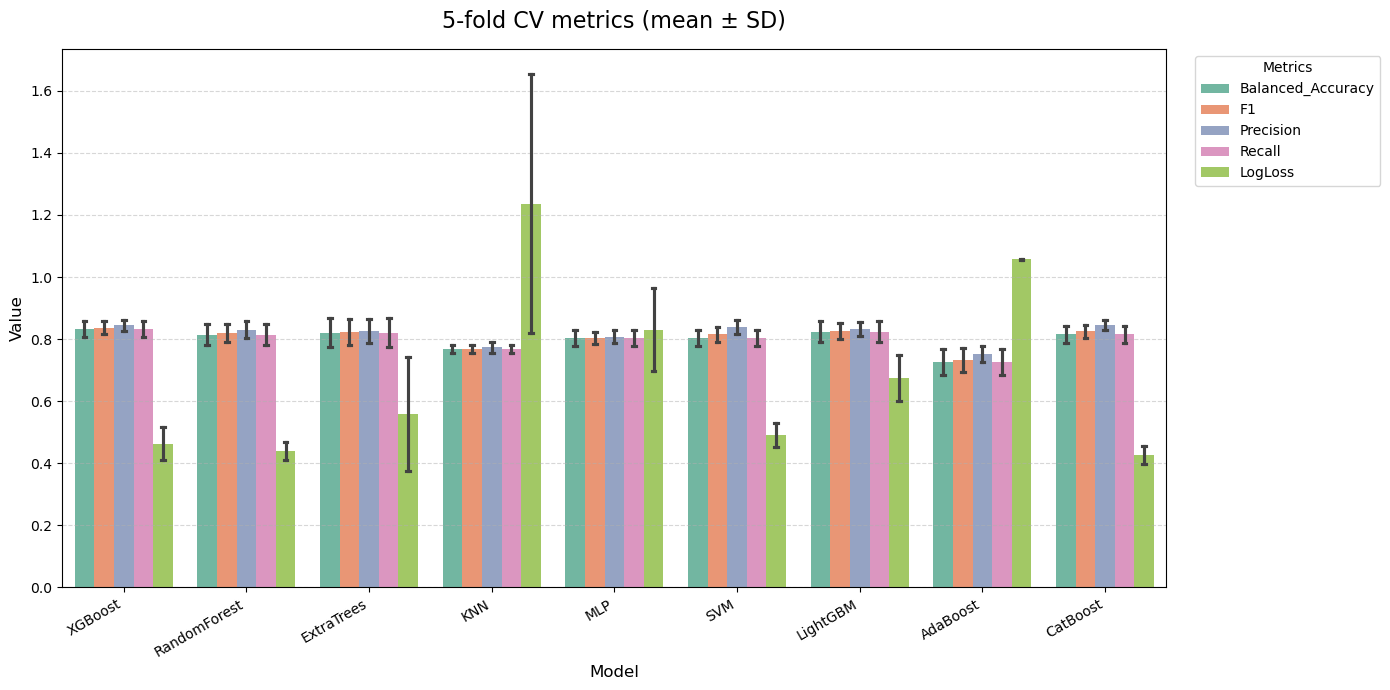

                          mean                                  \
Metric       Balanced_Accuracy     F1 LogLoss Precision Recall   
Model                                                            
AdaBoost                 0.727  0.733   1.058     0.751  0.727   
CatBoost                 0.815  0.825   0.427     0.845  0.815   
ExtraTrees               0.821  0.822   0.558     0.827  0.821   
KNN                      0.767  0.768   1.236     0.774  0.767   
LightGBM                 0.824  0.826   0.675     0.834  0.824   
MLP                      0.804  0.803   0.829     0.808  0.804   
RandomForest             0.814  0.819   0.439     0.831  0.814   
SVM                      0.802  0.816   0.491     0.839  0.802   
XGBoost                  0.833  0.836   0.463     0.845  0.833   

                            sd                                  
Metric       Balanced_Accuracy     F1 LogLoss Precision Recall  
Model                                                           
AdaBoost    

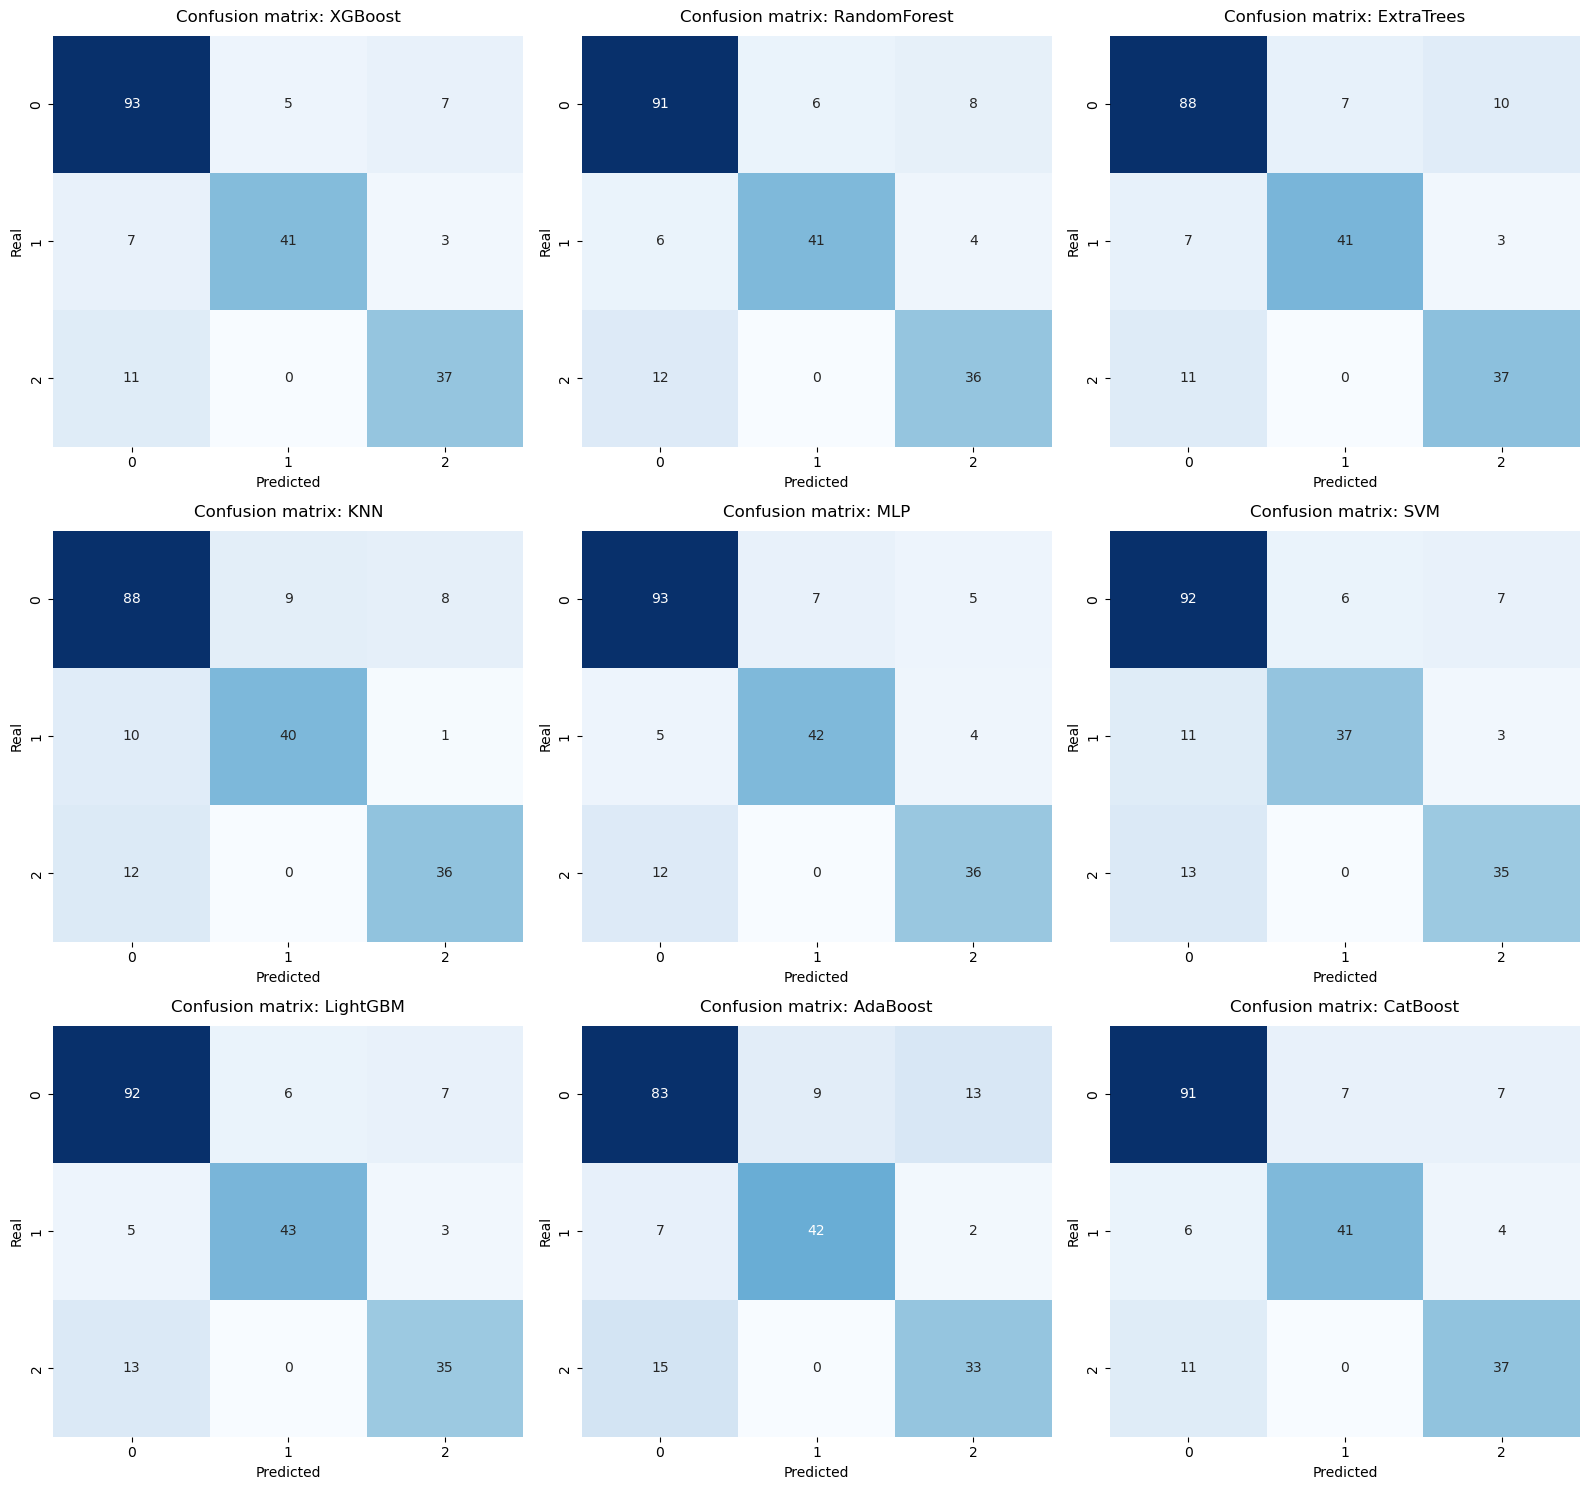

In [6]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix, balanced_accuracy_score, f1_score, precision_score, recall_score, log_loss)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
set_seed(42)

# Data 
df = pd.read_excel("DATA_CYP17.xlsx")
X = df.drop('Name', axis=1)
y_cat = df['Name'].astype('category')
y = y_cat.cat.codes.values
class_names = [str(c) for c in y_cat.cat.categories]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# Models
models = {
    "XGBoost": xgb.XGBClassifier(
        n_estimators=400, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        objective="multi:softprob", num_class=len(class_names),
        random_state=42, eval_metric="mlogloss"),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=300, random_state=42),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=7))]),
    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=2000, random_state=42)) ]),
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(probability=True, kernel="rbf", C=1.0, random_state=42))]),
    "LightGBM": lgb.LGBMClassifier(
        n_estimators=400, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        random_state=42, verbose=-1),
    "AdaBoost": AdaBoostClassifier(n_estimators=300, random_state=42),
    "CatBoost": CatBoostClassifier(
        iterations=400, depth=6, learning_rate=0.05,
        loss_function="MultiClass", random_seed=42, verbose=False)}

# Metrics
scoring_metrics = {
    "Balanced_Accuracy": "balanced_accuracy",
    "F1": "f1_macro",
    "Precision": "precision_macro",
    "Recall": "recall_macro",
    "LogLoss": "neg_log_loss"}

results_list = []
conf_matrices = {}
cv_folds_list = []   
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    print(f"Evaluation: {name}...")

    cv_scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring_metrics)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test) if hasattr(model, "predict_proba") else None

    conf_matrices[name] = confusion_matrix(y_test, y_pred)

    row = {"Model": name}

    for metric_name in scoring_metrics:
        vals = cv_scores[f"test_{metric_name}"]
        if metric_name == "LogLoss":
            vals = -vals                                 
        row[f"CV_{metric_name}"] = vals.mean()
        row[f"CV_{metric_name}_std"] = vals.std(ddof=1)   
        for fold, v in enumerate(vals, start=1):
            cv_folds_list.append({"Model": name, "Metric": metric_name,
                                  "Fold": fold, "Value": v})

    row["Balanced_Accuracy"] = balanced_accuracy_score(y_test, y_pred)
    row["F1"] = f1_score(y_test, y_pred, average="macro")
    row["Precision"] = precision_score(y_test, y_pred, average="macro", zero_division=0)
    row["Recall"] = recall_score(y_test, y_pred, average="macro")
    row["LogLoss"] = log_loss(y_test, y_proba) if y_proba is not None else np.nan

    results_list.append(row)

results_df = pd.DataFrame(results_list)

# Graphs
cv_folds_df = pd.DataFrame(cv_folds_list)
model_order = list(models.keys())
metric_order = list(scoring_metrics.keys())

fig, ax = plt.subplots(figsize=(14, 7))

sns.barplot( data=cv_folds_df, x="Model", y="Value", hue="Metric",order=model_order, hue_order=metric_order, palette="Set2", errorbar="sd", capsize=0.15, ax=ax)

ax.legend(title="Metrics", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title("5-fold CV metrics (mean ± SD)", fontsize=16, pad=15)
ax.set_ylabel("Value", fontsize=12)
ax.set_xlabel("Model", fontsize=12)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("cv_all_metrics_600dpi.tiff", dpi=600)
plt.show()

summary = (cv_folds_df.groupby(["Model", "Metric"])["Value"]
           .agg(mean="mean", sd="std").round(3).unstack("Metric"))
summary.to_csv("cv_mean_sd.csv")
print(summary)

# Confusion matrices
n_models = len(conf_matrices)
cols_grid = 3
rows_grid = int(np.ceil(n_models / cols_grid))
fig, axes = plt.subplots(rows_grid, cols_grid, figsize=(16, 5 * rows_grid))
axes = axes.flatten()

for idx, (name, cm) in enumerate(conf_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[idx], cbar=False)
    axes[idx].set_title(f'Confusion matrix: {name}', fontsize=12, pad=10)
    axes[idx].set_xlabel('Predicted', fontsize=10)
    axes[idx].set_ylabel('Real', fontsize=10)

for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig("confusion_matrices_9Models_600dpi.tiff", dpi=600)
plt.show()


In [2]:
results_df = pd.DataFrame(results_list)

In [3]:
# Metrics on test split
test_cols = ["Model", "Balanced_Accuracy", "F1", "Precision", "Recall", "LogLoss"]
test_table = results_df[test_cols].copy()

print("\n  Metrics")
print(test_table.to_string(index=False))



  Metrics
       Model  Balanced_Accuracy       F1  Precision   Recall  LogLoss
     XGBoost           0.820156 0.828473   0.838792 0.820156 0.574794
RandomForest           0.806863 0.812401   0.819068 0.806863 0.454312
  ExtraTrees           0.804283 0.805836   0.808118 0.804283 1.141064
         KNN           0.790803 0.797599   0.805442 0.790803 1.631348
         MLP           0.819748 0.826437   0.834199 0.819748 0.871083
         SVM           0.776949 0.790834   0.810449 0.776949 0.488621
    LightGBM           0.816165 0.822834   0.830564 0.816165 1.010036
    AdaBoost           0.767169 0.767169   0.767169 0.767169 1.058610
    CatBoost           0.813807 0.817859   0.822531 0.813807 0.445198


Accuracy: 0.8529
Balanced Accuracy: 0.8398
Precision (macro): 0.8485
Recall (macro): 0.8398
F1 Macro: 0.8439
Log Loss: 0.4322

Classification Report:

              precision    recall  f1-score   support

           0       0.86      0.89      0.87       105
           1       0.88      0.86      0.87        51
           2       0.80      0.77      0.79        48

    accuracy                           0.85       204
   macro avg       0.85      0.84      0.84       204
weighted avg       0.85      0.85      0.85       204

ROC-AUC (class 0): 0.9139
ROC-AUC (class 1): 0.9665
ROC-AUC (class 2): 0.9183


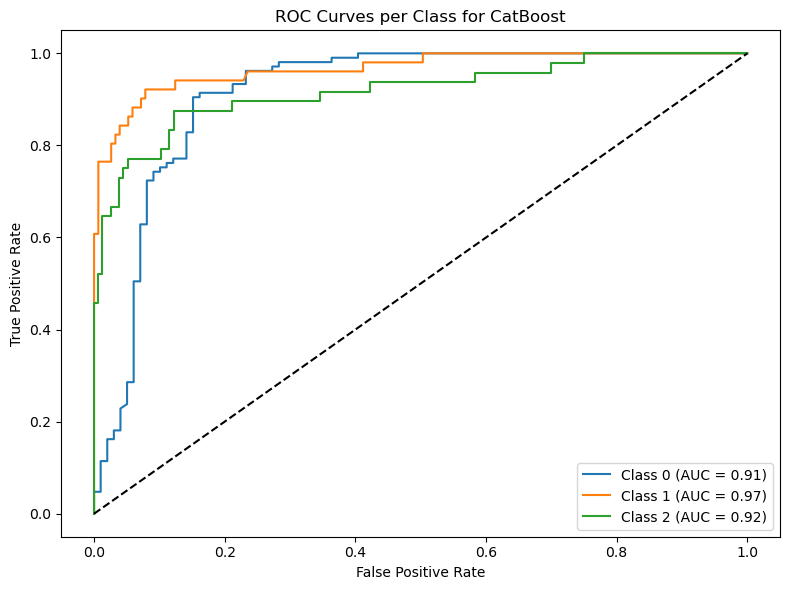

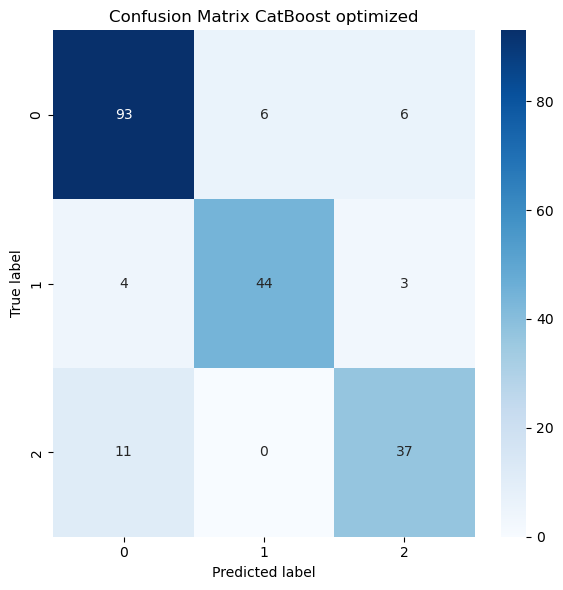

['catboost_best.pkl']

In [4]:
# CatBoost best HP 
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, balanced_accuracy_score, log_loss, classification_report, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
set_seed(42)


df = pd.read_excel("DATA_CYP17.xlsx")
X = df.drop('Name', axis=1)
y_cat = df['Name'].astype('category')
y = y_cat.cat.codes.values
class_names = [str(c) for c in y_cat.cat.categories]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

#  Optimal HP
best_cat = CatBoostClassifier(
    iterations=576,
    depth=8,
    learning_rate=0.04830916201176393,
    l2_leaf_reg=3,
    bagging_temperature=1.4964928980911067,
    random_strength=3.5710417720119474,
    border_count=77,
    min_data_in_leaf=4,
    grow_policy="SymmetricTree",
    loss_function="MultiClass",
    random_seed=42,
    verbose=0)

best_cat.fit(X_train, y_train)
 
y_proba = best_cat.predict_proba(X_test)
y_pred = np.argmax(y_proba, axis=1)

# Metrics
print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}')
print(f'Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}')
print(f'Precision (macro): {precision_score(y_test, y_pred, average="macro", zero_division=0):.4f}')
print(f'Recall (macro): {recall_score(y_test, y_pred, average="macro", zero_division=0):.4f}')
print(f'F1 Macro: {f1_score(y_test, y_pred, average="macro", zero_division=0):.4f}')
print(f'Log Loss: {log_loss(y_test, y_proba, labels=list(range(len(class_names)))):.4f}')

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=class_names))

roc_auc_per_class = roc_auc_score(y_test, y_proba, average=None, multi_class="ovr")
for idx, score in enumerate(roc_auc_per_class):
    print(f"ROC-AUC (class {class_names[idx]}): {score:.4f}")

plt.figure(figsize=(8,6))
for i in range(len(class_names)):
    fpr, tpr, _ = roc_curve(y_test == i, y_proba[:, i])
    plt.plot(fpr, tpr, label=f"Class {class_names[i]} (AUC = {roc_auc_per_class[i]:.2f})")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves per Class for CatBoost")
plt.legend()
plt.tight_layout()
plt.savefig("OVR-ROC_CatBoost_optimal.tiff", dpi=600, bbox_inches="tight")
plt.show()

# Confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix CatBoost optimized')
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.savefig("Conf_Matrtix_CatBoost_optima.tiff", dpi=600, bbox_inches="tight")
plt.show()

# Saving 
joblib.dump(best_cat, "catboost_best.pkl")


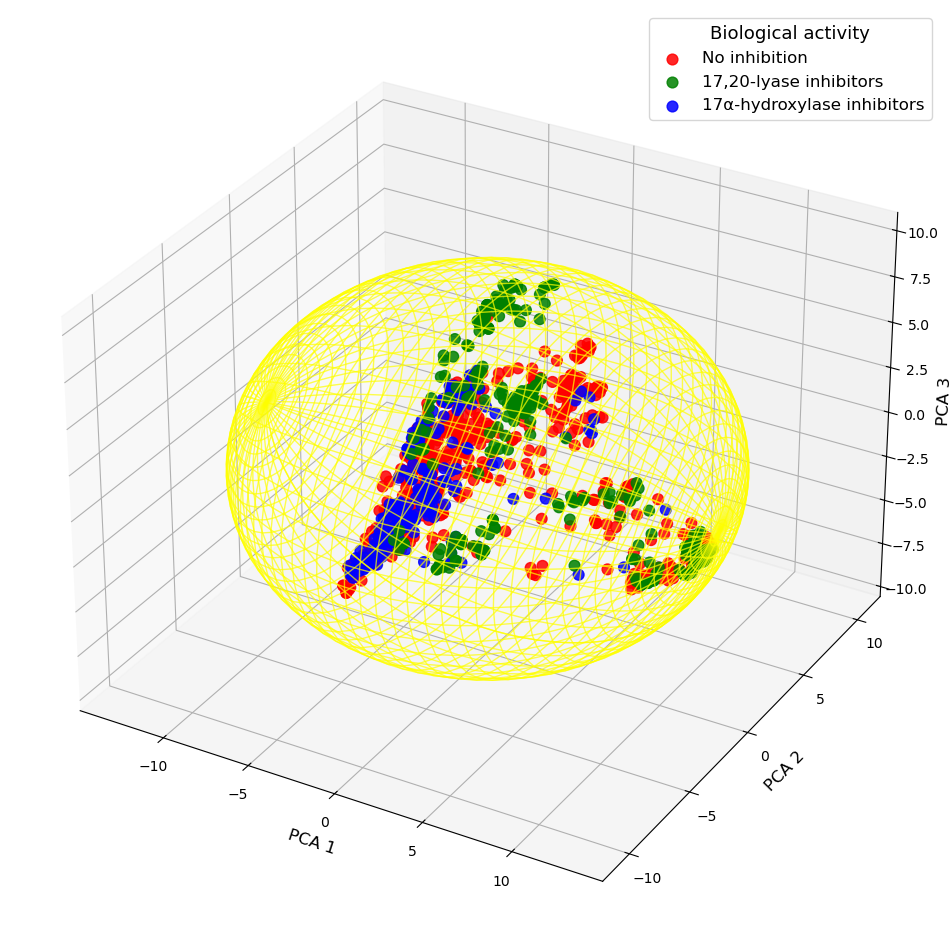

In [5]:
#Applicability domain
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.stats import chi2
from mpl_toolkits.mplot3d import Axes3D

df = pd.read_excel('DATA_CYP17.xlsx')
X = df.drop('Name', axis=1)
y = df['Name']

class_map = { 0: "No inhibition", 1: "17,20-lyase inhibitors", 2: "17α-hydroxylase inhibitors"}

y_named = y.map(class_map)

colors = {"No inhibition": "red", "17,20-lyase inhibitors": "green", "17α-hydroxylase inhibitors": "blue"}

pca = PCA(n_components=3, random_state=42)
X_pca3 = pca.fit_transform(X)

center = X_pca3.mean(axis=0)
cov = np.cov(X_pca3.T)
inv_cov = np.linalg.inv(cov)

def mahalanobis(x, mean, inv_cov):
    diff = x - mean
    return np.sqrt(diff.T @ inv_cov @ diff)

distances = np.array([mahalanobis(x, center, inv_cov) for x in X_pca3])
threshold = np.sqrt(chi2.ppf(0.95, df=3))
eigvals, eigvecs = np.linalg.eigh(cov)
rx, ry, rz = threshold * np.sqrt(eigvals)

u = np.linspace(0, 2 * np.pi, 50)
v = np.linspace(0, np.pi, 50)

xs = rx * np.outer(np.cos(u), np.sin(v))
ys = ry * np.outer(np.sin(u), np.sin(v))
zs = rz * np.outer(np.ones_like(u), np.cos(v))

ellipsoid = eigvecs @ np.array([xs.flatten(), ys.flatten(), zs.flatten()])
xs_e = ellipsoid[0, :].reshape(xs.shape) + center[0]
ys_e = ellipsoid[1, :].reshape(ys.shape) + center[1]
zs_e = ellipsoid[2, :].reshape(zs.shape) + center[2]

# Graph
fig = plt.figure(figsize=(12, 15))
ax = fig.add_subplot(111, projection='3d')

for cls in class_map.values():
    mask = (y_named == cls)
    ax.scatter(
        X_pca3[mask, 0],
        X_pca3[mask, 1],
        X_pca3[mask, 2],
        s=60,
        alpha=0.85,
        color=colors[cls],
        label=cls)

ax.plot_wireframe(
    xs_e, ys_e, zs_e,
    rstride=1, cstride=1,
    color='yellow',
    linewidth=1.0,
    linestyle='-',
    alpha=0.7)
ax.set_xlabel("PCA 1", fontsize=12)
ax.set_ylabel("PCA 2", fontsize=12)
ax.set_zlabel("PCA 3", fontsize=12)
ax.legend(title="Biological activity", fontsize=12, title_fontsize=13)

plt.savefig("Applicability domain_CYP17.tiff", dpi=600, bbox_inches="tight")
plt.show()
